# 06 · Energy usage

Basic look at household consumption and battery state from the inverter snapshots: average power per hour of day (local time) and the battery charge range per day / per hour.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from common import load_snapshots

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True

In [2]:
snapshots = load_snapshots().tz_convert(TZ)
snapshots["hour"] = snapshots.index.hour
snapshots["day"] = snapshots.index.date
print(f"{len(snapshots)} readings, {snapshots.index.min()} → {snapshots.index.max()}")
snapshots[["load_power_w", "solar_power_w", "grid_power_w",
           "battery_power_w", "battery_charge_pct"]].describe().round(1)

19152 readings, 2026-10-25 11:45:56.585000+02:00 → 2026-11-07 20:15:00.935268+02:00


,load_power_w,solar_power_w,grid_power_w,battery_power_w,battery_charge_pct
count,19152.0,19152.0,19152.0,19152.0,19152.0
mean,422.2,136.0,327.7,-26.4,88.8
std,321.7,352.8,867.3,915.3,11.6
min,0.0,0.0,-178.0,-3554.0,55.0
25%,276.0,0.0,0.0,-46.0,81.0
50%,367.0,0.0,0.0,158.0,94.0
75%,476.0,138.0,203.0,398.0,98.0
max,4706.0,3467.0,3452.0,4834.0,100.0


In [13]:
snapshots.head()

,id,solar_power_w,load_power_w,grid_power_w,battery_power_w,battery_charge_pct,battery_voltage_v,grid_voltage_v,battery_max_charge_current_a,pv1_current_a,pv1_power_w,pv1_voltage_v,pv2_current_a,pv2_power_w,pv2_voltage_v,state,headroom,hour,day
timestamp,,,,,,,,,,,,,,,,,,,
2026-10-25 11:45:56.585000+02:00,8,363,460,0,71,95,53.26,34.5,65,1.1,363,328.1,0,0,1.6,unconstrained,False,11,2026-10-25
2026-10-25 11:47:32.667000+02:00,9,366,439,0,46,95,53.25,34.5,65,1.1,366,322.1,0,0,1.6,unconstrained,False,11,2026-10-25
2026-10-25 11:47:43.614000+02:00,10,365,438,0,46,95,53.26,34.5,65,1.1,365,322.6,0,0,1.6,unconstrained,False,11,2026-10-25
2026-10-25 11:48:03.607000+02:00,11,361,445,0,58,95,53.26,34.4,65,1.1,361,325.1,0,0,1.6,unconstrained,False,11,2026-10-25
2026-10-25 12:15:34.285182+02:00,12,562,473,0,-113,94,53.23,34.5,65,1.7,562,325.1,0,0,1.7,unconstrained,True,12,2026-10-25


## Average power per hour of day

Mean of all readings in each local hour across all days; the band is the 25–75 % range of load. Readings are ~2 min apart, so the hourly mean in W equals the average energy per hour in Wh.

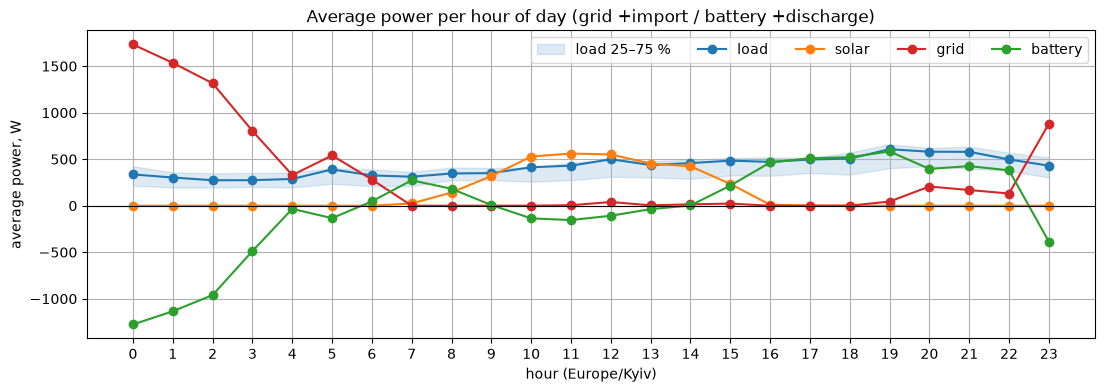

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
load_power_w,336,303,274,274,287,390,326,311,346,350,...,457,484,471,497,506,607,580,579,497,430
solar_power_w,0,0,0,0,0,0,0,24,142,319,...,424,234,10,0,0,0,0,0,0,0
grid_power_w,1733,1536,1316,804,329,540,281,0,0,0,...,15,22,0,0,0,45,206,169,131,882
battery_power_w,-1277,-1135,-961,-488,-34,-134,47,273,182,7,...,2,216,465,510,521,583,396,426,380,-387


In [3]:
POWER_COLS = ["load_power_w", "solar_power_w", "grid_power_w", "battery_power_w"]
by_hour = snapshots.groupby("hour")[POWER_COLS].mean()
load_q = snapshots.groupby("hour")["load_power_w"].quantile([0.25, 0.75]).unstack()

fig, ax = plt.subplots()
ax.fill_between(load_q.index, load_q[0.25], load_q[0.75],
                color="tab:blue", alpha=0.15, label="load 25–75 %")
for col, color in zip(POWER_COLS, ["tab:blue", "tab:orange", "tab:red", "tab:green"]):
    ax.plot(by_hour.index, by_hour[col], marker="o", color=color,
            label=col.removesuffix("_power_w"))
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(24))
ax.set_xlabel(f"hour ({TZ})")
ax.set_ylabel("average power, W")
ax.set_title("Average power per hour of day (grid +import / battery +discharge)")
ax.legend(ncol=5)
plt.show()

by_hour.round(0).astype(int).T

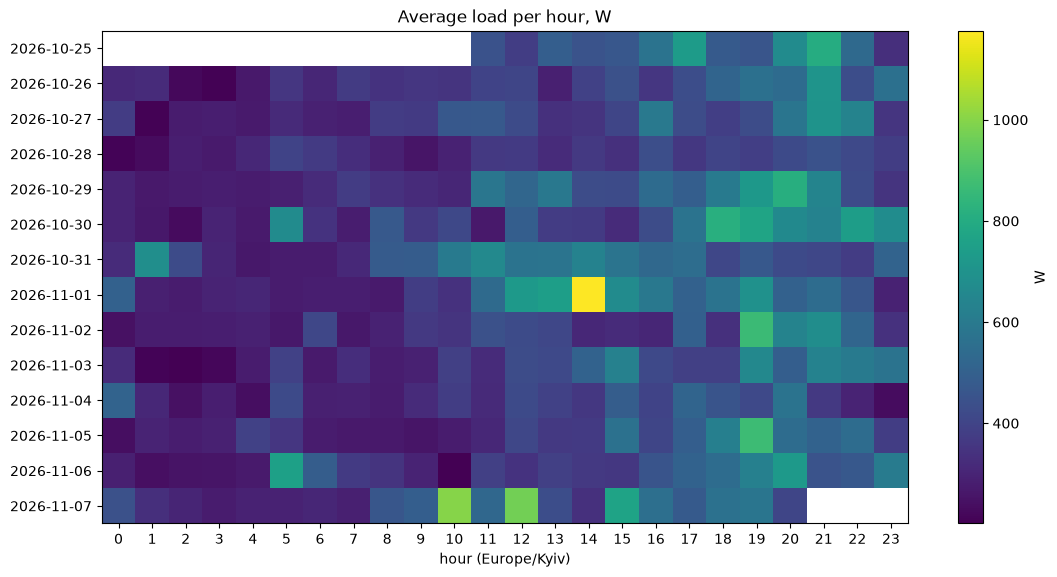

In [4]:
# Average load per hour for each day: shows how stable the daily pattern is.
load_day_hour = snapshots.pivot_table(index="day", columns="hour",
                                      values="load_power_w", aggfunc="mean")
fig, ax = plt.subplots(figsize=(13, 0.35 * len(load_day_hour) + 1.5))
im = ax.imshow(load_day_hour, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(load_day_hour.columns)), load_day_hour.columns)
ax.set_yticks(range(len(load_day_hour)), [str(d) for d in load_day_hour.index])
ax.set_xlabel(f"hour ({TZ})")
ax.set_title("Average load per hour, W")
ax.grid(False)
fig.colorbar(im, ax=ax, label="W")
plt.show()

In [5]:
dkwh = snapshots.copy()
dkwh["load_power_w"] = dkwh["load_power_w"] + 100

In [6]:
dkwh.describe()

,id,solar_power_w,load_power_w,grid_power_w,battery_power_w,battery_charge_pct,battery_voltage_v,grid_voltage_v,battery_max_charge_current_a,pv1_current_a,pv1_power_w,pv1_voltage_v,pv2_current_a,pv2_power_w,pv2_voltage_v,hour
count,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.0,19152.000000,19152.000000,19152.000000,19152.0,19152.0,19152.000000,19152.000000
mean,9583.500000,136.022661,522.166197,327.706610,-26.374791,88.765873,53.600008,125.964515,65.0,0.406396,136.022661,143.888565,0.0,0.0,1.653817,11.612886
std,5528.850513,352.790093,321.713956,867.308564,915.309618,11.582006,0.995086,103.244738,0.0,1.073379,352.790093,134.472963,0.0,0.0,1.220215,6.881491
min,8.000000,0.000000,100.000000,-178.000000,-3554.000000,55.000000,51.630000,2.600000,65.0,0.000000,0.000000,12.300000,0.0,0.0,0.700000,0.000000
25%,4795.750000,0.000000,376.000000,0.000000,-46.000000,81.000000,53.000000,10.800000,65.0,0.000000,0.000000,29.100000,0.0,0.0,0.800000,6.000000
50%,9583.500000,0.000000,467.000000,0.000000,158.000000,94.000000,53.150000,206.000000,65.0,0.000000,0.000000,61.600000,0.0,0.0,0.900000,12.000000
75%,14371.250000,138.000000,576.000000,203.000000,398.000000,98.000000,54.262500,227.200000,65.0,0.400000,138.000000,314.525000,0.0,0.0,1.900000,18.000000
max,19159.000000,3467.000000,4806.000000,3452.000000,4834.000000,100.000000,56.030000,256.900000,65.0,10.500000,3467.000000,401.600000,0.0,0.0,4.300000,23.000000


In [7]:
snapshots.describe()

,id,solar_power_w,load_power_w,grid_power_w,battery_power_w,battery_charge_pct,battery_voltage_v,grid_voltage_v,battery_max_charge_current_a,pv1_current_a,pv1_power_w,pv1_voltage_v,pv2_current_a,pv2_power_w,pv2_voltage_v,hour
count,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.000000,19152.0,19152.000000,19152.000000,19152.000000,19152.0,19152.0,19152.000000,19152.000000
mean,9583.500000,136.022661,422.166197,327.706610,-26.374791,88.765873,53.600008,125.964515,65.0,0.406396,136.022661,143.888565,0.0,0.0,1.653817,11.612886
std,5528.850513,352.790093,321.713956,867.308564,915.309618,11.582006,0.995086,103.244738,0.0,1.073379,352.790093,134.472963,0.0,0.0,1.220215,6.881491
min,8.000000,0.000000,0.000000,-178.000000,-3554.000000,55.000000,51.630000,2.600000,65.0,0.000000,0.000000,12.300000,0.0,0.0,0.700000,0.000000
25%,4795.750000,0.000000,276.000000,0.000000,-46.000000,81.000000,53.000000,10.800000,65.0,0.000000,0.000000,29.100000,0.0,0.0,0.800000,6.000000
50%,9583.500000,0.000000,367.000000,0.000000,158.000000,94.000000,53.150000,206.000000,65.0,0.000000,0.000000,61.600000,0.0,0.0,0.900000,12.000000
75%,14371.250000,138.000000,476.000000,203.000000,398.000000,98.000000,54.262500,227.200000,65.0,0.400000,138.000000,314.525000,0.0,0.0,1.900000,18.000000
max,19159.000000,3467.000000,4706.000000,3452.000000,4834.000000,100.000000,56.030000,256.900000,65.0,10.500000,3467.000000,401.600000,0.0,0.0,4.300000,23.000000


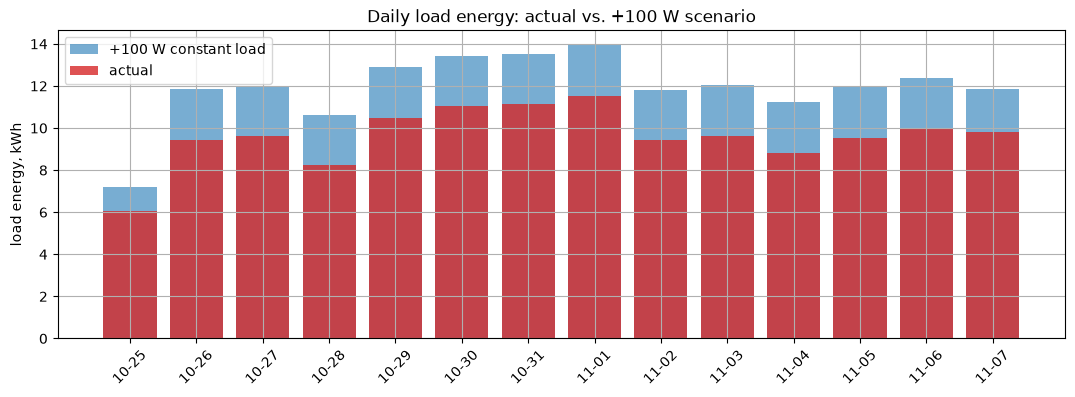

day,2026-10-25,2026-10-26,2026-10-27,2026-10-28,2026-10-29,2026-10-30,2026-10-31,2026-11-01,2026-11-02,2026-11-03,2026-11-04,2026-11-05,2026-11-06,2026-11-07
actual,6.06,9.43,9.61,8.23,10.49,11.03,11.13,11.54,9.42,9.63,8.83,9.54,10.0,9.81
+100 W,7.18,11.83,12.00,10.63,12.89,13.43,13.53,13.94,11.82,12.03,11.23,11.93,12.4,11.84
extra,1.12,2.40,2.40,2.40,2.40,2.40,2.40,2.40,2.40,2.40,2.41,2.38,2.4,2.03


In [8]:
# Daily load energy: actual vs. scenario with a constant extra 100 W load (dkwh).
# Both on one axis at the same x positions; the taller scenario bar is drawn behind,
# so the visible blue cap on top of each red bar is the extra energy of the scenario.
daily_kwh = snapshots.groupby("day")["load_power_w"].sum() / 60 / 1000
daily_kwh2 = dkwh.groupby("day")["load_power_w"].sum() / 60 / 1000

fig, ax = plt.subplots()
x = range(len(daily_kwh))
ax.bar(x, daily_kwh2, width=0.8, color="tab:blue", alpha=0.6, label="+100 W constant load")
ax.bar(x, daily_kwh, width=0.8, color="tab:red", alpha=0.8, label="actual")
ax.set_xticks(list(x), [str(d)[5:] for d in daily_kwh.index], rotation=45)
ax.set_ylabel("load energy, kWh")
ax.set_title("Daily load energy: actual vs. +100 W scenario")
ax.legend()
plt.show()

pd.DataFrame({"actual": daily_kwh, "+100 W": daily_kwh2,
              "extra": daily_kwh2 - daily_kwh}).round(2).T

## Battery charge: min / max

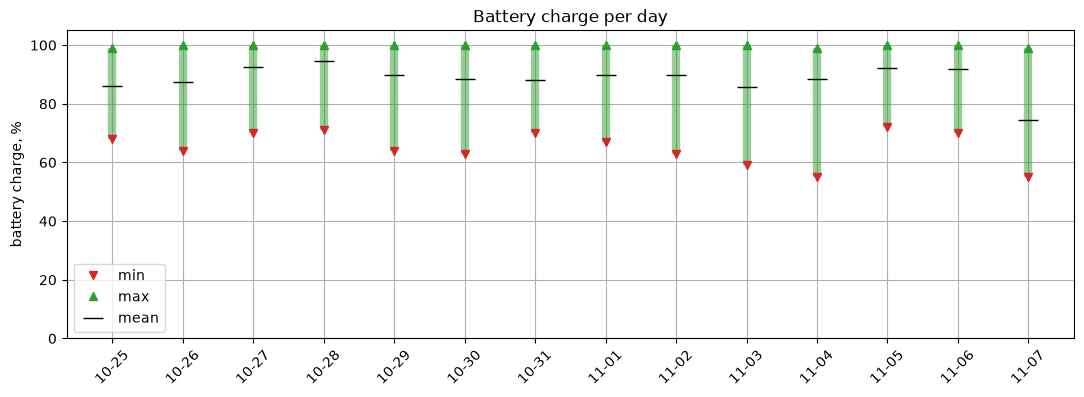

day,2026-10-25,2026-10-26,2026-10-27,2026-10-28,2026-10-29,2026-10-30,2026-10-31,2026-11-01,2026-11-02,2026-11-03,2026-11-04,2026-11-05,2026-11-06,2026-11-07
min,68.0,64.0,70.0,71.0,64.0,63.0,70.0,67.0,63.0,59.0,55.0,72.0,70.0,55.0
mean,86.2,87.5,92.4,94.6,89.7,88.3,88.1,89.7,89.9,85.6,88.6,92.2,91.9,74.4
max,99.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,99.0,100.0,100.0,99.0


In [9]:
battery_daily = snapshots.groupby("day")["battery_charge_pct"].agg(["min", "mean", "max"])

fig, ax = plt.subplots()
x = range(len(battery_daily))
ax.vlines(x, battery_daily["min"], battery_daily["max"], color="tab:green", lw=6, alpha=0.5)
ax.plot(x, battery_daily["min"], "v", color="tab:red", label="min")
ax.plot(x, battery_daily["max"], "^", color="tab:green", label="max")
ax.plot(x, battery_daily["mean"], "_", color="black", ms=14, label="mean")
ax.set_xticks(list(x), [str(d)[5:] for d in battery_daily.index], rotation=45)
ax.set_ylim(0, 105)
ax.set_ylabel("battery charge, %")
ax.set_title("Battery charge per day")
ax.legend()
plt.show()

battery_daily.round(1).T

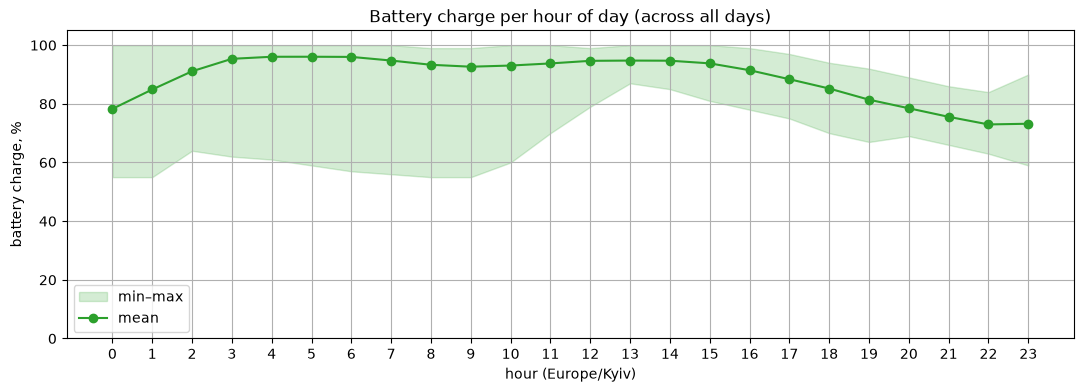

In [10]:
battery_hour = snapshots.groupby("hour")["battery_charge_pct"].agg(["min", "mean", "max"])

fig, ax = plt.subplots()
ax.fill_between(battery_hour.index, battery_hour["min"], battery_hour["max"],
                color="tab:green", alpha=0.2, label="min–max")
ax.plot(battery_hour.index, battery_hour["mean"], marker="o", color="tab:green", label="mean")
ax.set_xticks(range(24))
ax.set_ylim(0, 105)
ax.set_xlabel(f"hour ({TZ})")
ax.set_ylabel("battery charge, %")
ax.set_title("Battery charge per hour of day (across all days)")
ax.legend()
plt.show()

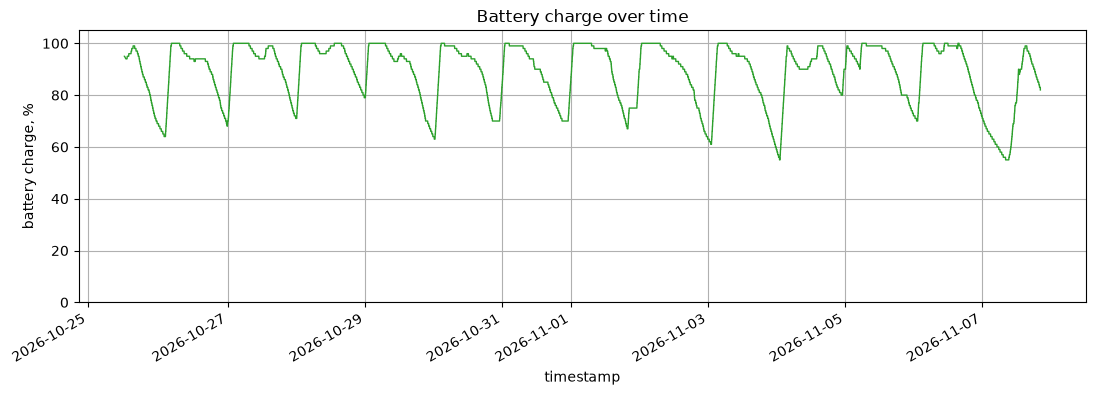

In [11]:
ax = snapshots["battery_charge_pct"].plot(color="tab:green", lw=1)
ax.set_ylim(0, 105)
ax.set_ylabel("battery charge, %")
ax.set_title("Battery charge over time")
plt.show()

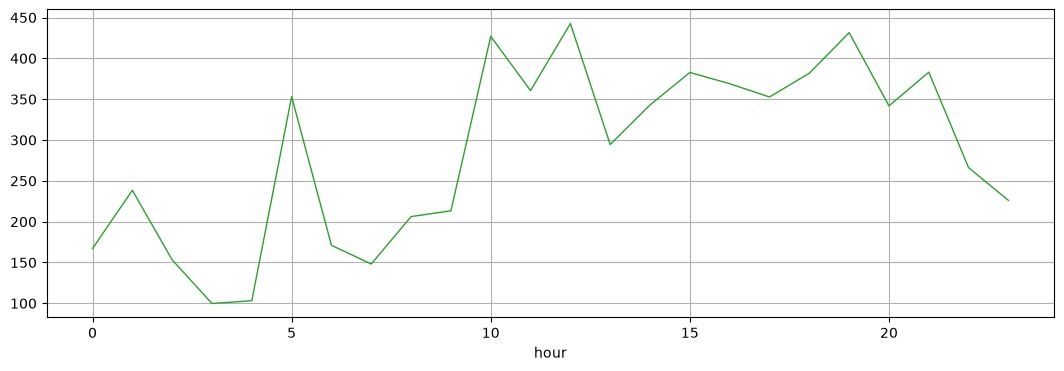

In [33]:
ax = snapshots.groupby("hour")["load_power_w"].std().plot(color="tab:green", lw=1)

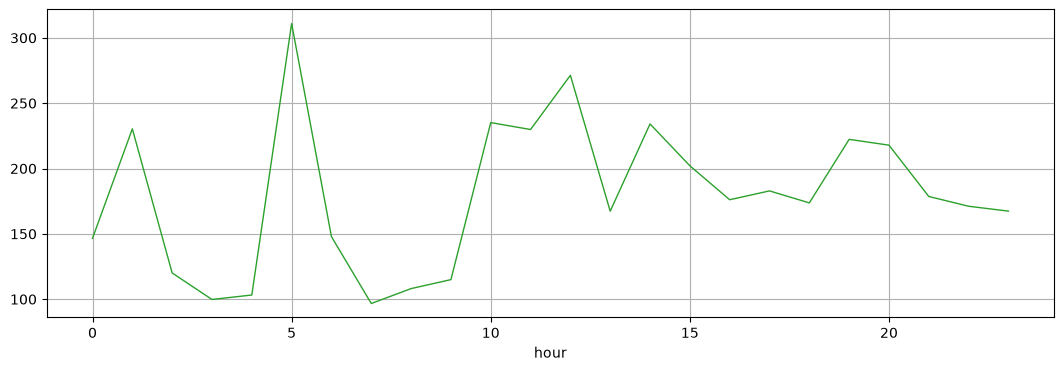

In [35]:
ax = snapshots[snapshots["load_power_w"] <= 2000].groupby("hour")["load_power_w"].std().plot(color="tab:green", lw=1)

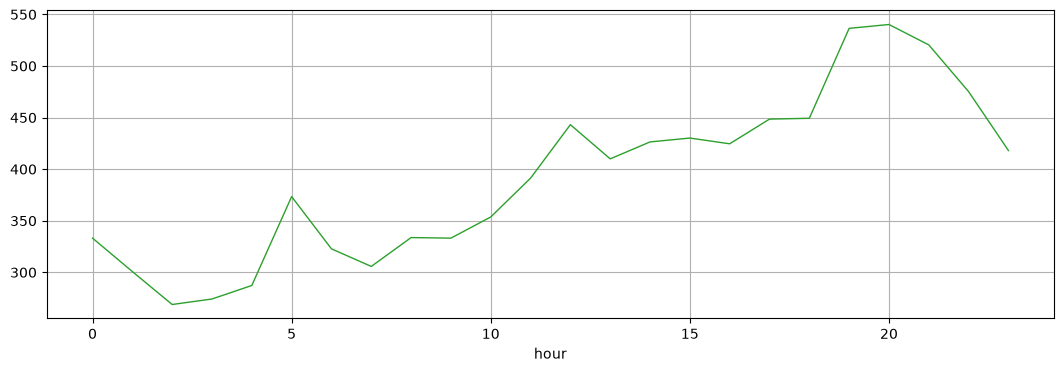

In [36]:
ax = snapshots[snapshots["load_power_w"] <= 2000].groupby("hour")["load_power_w"].mean().plot(color="tab:green", lw=1)

In [41]:
ax = snapshots.iloc[[5453, 9000, 20000], :]["load_power_w"].mean().plot(color="tab:green", lw=1)

IndexError: positional indexers are out-of-bounds